# Modeling single-cell proximity data from chromatin tracing experiments

#### A tutorial in using the `topic3d` software package

## Background

In this tutorial, we will
- load some in pairwise proximity data and visualize it
- train an LDA model on this data and evaluate the model's quality
- visualize the results of the modeling

Importing required modules

In [1]:
import subprocess
import joblib
import h5py

import numpy as np

import matplotlib.pyplot as plt

from scipy.spatial.distance import squareform
from topic3d.datatypes import PWProxArrayStack
from topic3d.results import Topic3DResult
from IPython.display import Image

### Visualizing the sample data

Here, we have two datasets - a training and a test from an ensemble of conformations obtained using the polymer simulation of a simple domain (see polymer and ensemble average proximity map below)

![](./attachments/simple-domain.svg)

In [3]:
data_train_sim = PWProxArrayStack(np.load("./data/sample_sim_train.npy"))
data_test_sim = PWProxArrayStack(np.load("./data/sample_sim_test.npy"))
data_train_sim.shape, data_test_sim.shape

((1440, 780), (360, 780))

Plotting random examples from this ensemble shows us the diversity in individual (read, "single-cell") maps. Our goal is to use LDA to decompose this data based on patterns in proximity co-occurrence. Since the red pixels indicate the regions in proximity, LDA simply needs to find patterns in pixel co-occurrence. 

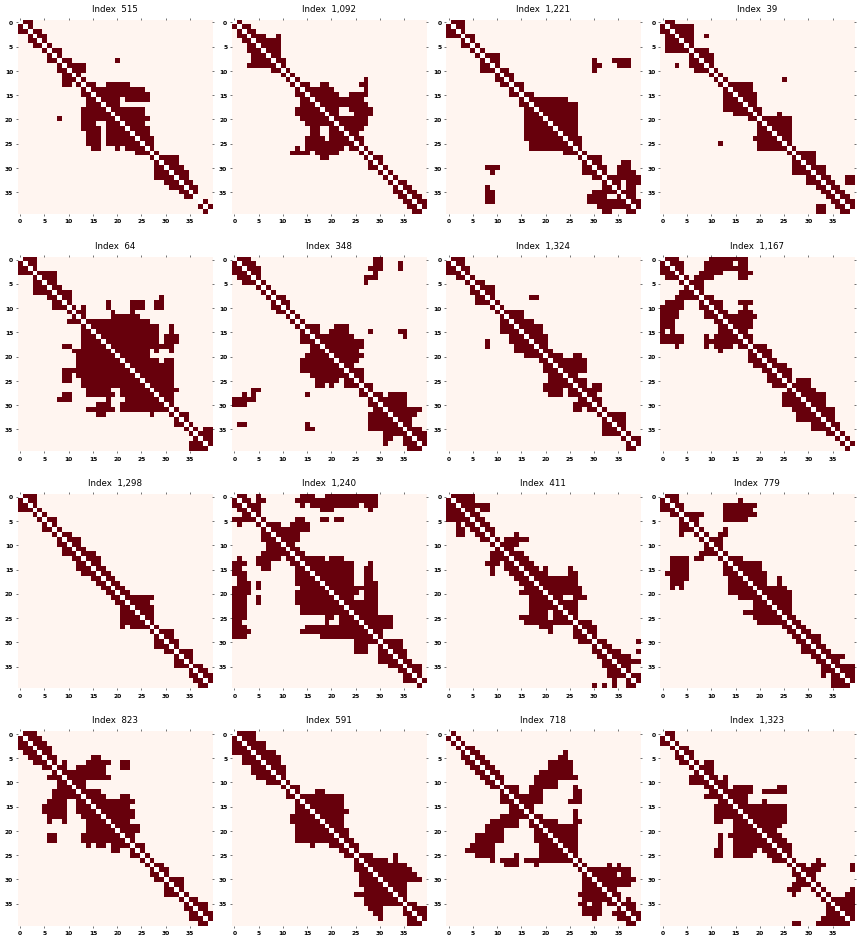

In [4]:
fig = data_train_sim.plot_random_examples(num_items=16,
                                          random_seed=None,
                                          form="square",
                                          include_cbar=False)
fig.set_dpi(48)
fig.show()

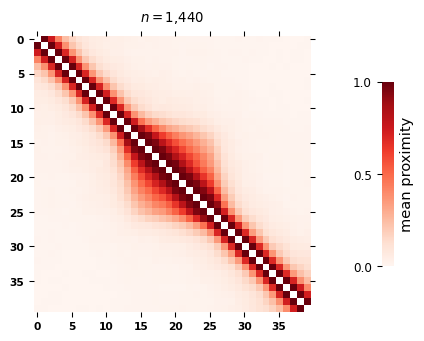

In [6]:
fig = data_train_sim.plot_ensemble_measure(method="mean", form="square", cbar_label="mean proximity")
fig.set_dpi(96)
fig.show()

### Model training and dataset decomposition

The following shell command is used to train an LDA model on a training dataset, and then transform the test dataset using the trained model. Here, we will use the `subprocess` to run the command in the notebook.

```bash
topic3d-decompose \
        --data_train_file ./data/sample_sim_train.npy \
        --data_test_file ./data/sample_sim_test.npy \
        --results_dir ./results/ \
        --num_components 4 \
        --max_iter 50 \
        --learning_method "batch" \
        --random_state 64
```

In [ ]:
subprocess.run([
    "topic3d-decompose",
    "--data_train_file", "./data/sample_sim_train.npy",
    "--data_test_file", "./data/sample_sim_test.npy",
    "--results_dir", "./results/",
    "--num_components", "4",
    "--max_iter", "50",
    "--learning_method", "batch",
    "--random_state", "64",
])

2026-02-23 17:16:48,516 [INFO] --------------------------------------------------
2026-02-23 17:16:48,516 [INFO] [e888c5] Will save trainings to: ./results/e888c5
2026-02-23 17:16:48,516 [INFO] Settings summary for run: e888c5
2026-02-23 17:16:48,516 [INFO]     data_train_file: ./data/sample_sim_train.npy
2026-02-23 17:16:48,516 [INFO]     data_test_file: ./data/sample_sim_test.npy
2026-02-23 17:16:48,517 [INFO]     results_dir: ./results/
2026-02-23 17:16:48,517 [INFO]     num_components: 4
2026-02-23 17:16:48,517 [INFO]     max_iter: 50
2026-02-23 17:16:48,517 [INFO]     learning_method: batch
2026-02-23 17:16:48,517 [INFO]     batch_size: 64
2026-02-23 17:16:48,517 [INFO]     random_state: 64
2026-02-23 17:16:48,517 [INFO]     uid: e888c5
2026-02-23 17:16:48,517 [INFO]     path_to_data: ['./data/sample_sim_train.npy', './data/sample_sim_test.npy']
2026-02-23 17:16:48,517 [INFO]     path_to_training: ./results/e888c5
2026-02-23 17:16:48,517 [INFO]     path_to_log: ./results/e888c5/lo

CompletedProcess(args=['topic3d-decompose', '--data_train_file', './data/sample_sim_train.npy', '--data_test_file', './data/sample_sim_test.npy', '--results_dir', './results/', '--num_components', '4', '--max_iter', '50', '--learning_method', 'batch', '--random_state', '64'], returncode=0)

In [7]:
training_id = "e888c5"    # set manually after training

We can check the model's perplexity on the training set (first code block below) and on the training set. Lower perplexity generally means that the model learnt to see patterns in the data better, although this may not always mean that the model generates interpretable results.

In [8]:
# On the training dataset
model = joblib.load(filename=f"./results/{training_id}/model_lda.jl")
model.bound_

np.float64(280.2184231458968)

In [9]:
# On the testing dataset (approx.)
model.perplexity(data_test_sim)

np.float64(312.0495216544464)

### Visualising the results

Loading them using a special class called `DecompositionResult` (from the `topic3d.handlers` module) for faster access to results and easier plotting.

To load the results, which are stored in H5 files as nested groups (see documentation), we need the function below.

In [10]:
def hdf5_group_to_dict(h5obj):
    """
    Recursively convert an HDF5 group or file into a nested Python dictionary.

    Parameters
    ----------
    h5obj : h5py.Group or h5py.File
        HDF5 object to convert.

    Returns
    -------
    dict
        Nested dictionary representation of the HDF5 structure.
    """

    out = {}

    # Add attributes (if any)
    if hasattr(h5obj, "attrs") and len(h5obj.attrs) > 0:
        out["_attrs"] = {k: v for k, v in h5obj.attrs.items()}

    for key, item in h5obj.items():

        # If subgroup → recurse
        if isinstance(item, h5py.Group):
            out[key] = hdf5_group_to_dict(item)

        # If dataset → extract data
        elif isinstance(item, h5py.Dataset):
            data = item[()]

            # Convert bytes to string if needed
            if isinstance(data, bytes):
                data = data.decode("utf-8")

            # Convert scalar numpy types to Python types
            if isinstance(data, np.generic):
                data = data.item()

            out[key] = data

    return out

In [11]:
with h5py.File(f"./results/{training_id}/results.h5", mode="r") as handler:
    decomposition = handler["decomposition"][:]
    coherence = hdf5_group_to_dict(handler["coherence"])
# pass the trained model and results
results_sim = Topic3DResult(model=model, decomposition=decomposition)

The Normalized Pointwise Mutual Information coherence for each component of this trained model with the training data, taking different top `npx` pixels, would be:

In [12]:
coherence["npmi"].keys()

dict_keys(['10', '2.5', '5', '7.5'])

In [13]:
coherence["npmi"]["2.5"]

array([-0.52577687,  0.26507357,  0.32982408,  0.22816055])

The normalized between [-1,+1] resulting in -1 (in the limit) for never occurring together, 0 for independence, and +1 for complete co-occurrence.

Plotting the components from the training data shows latent proximity co-occurrence patterns. In this case, since the only two ingredients of our polymer simulation are the usual polymer connectivity and the domain in the middle, they are the ones with high representativity in the dataset.

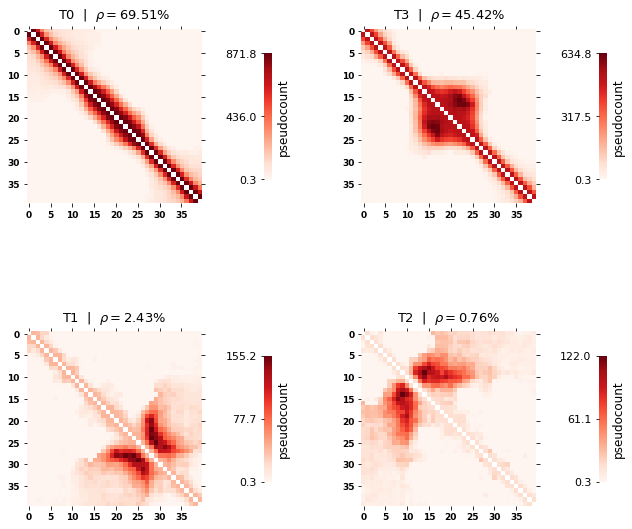

In [14]:
fig = results_sim.plot_components(ordered=True, form="square")
fig.set_dpi(72)
fig.show()

For a suitable number of components, a quick check is to compute the Jensen-Shannon divergence between the components. A higher pairwise divergence implies that the corresponding components have little overlap.

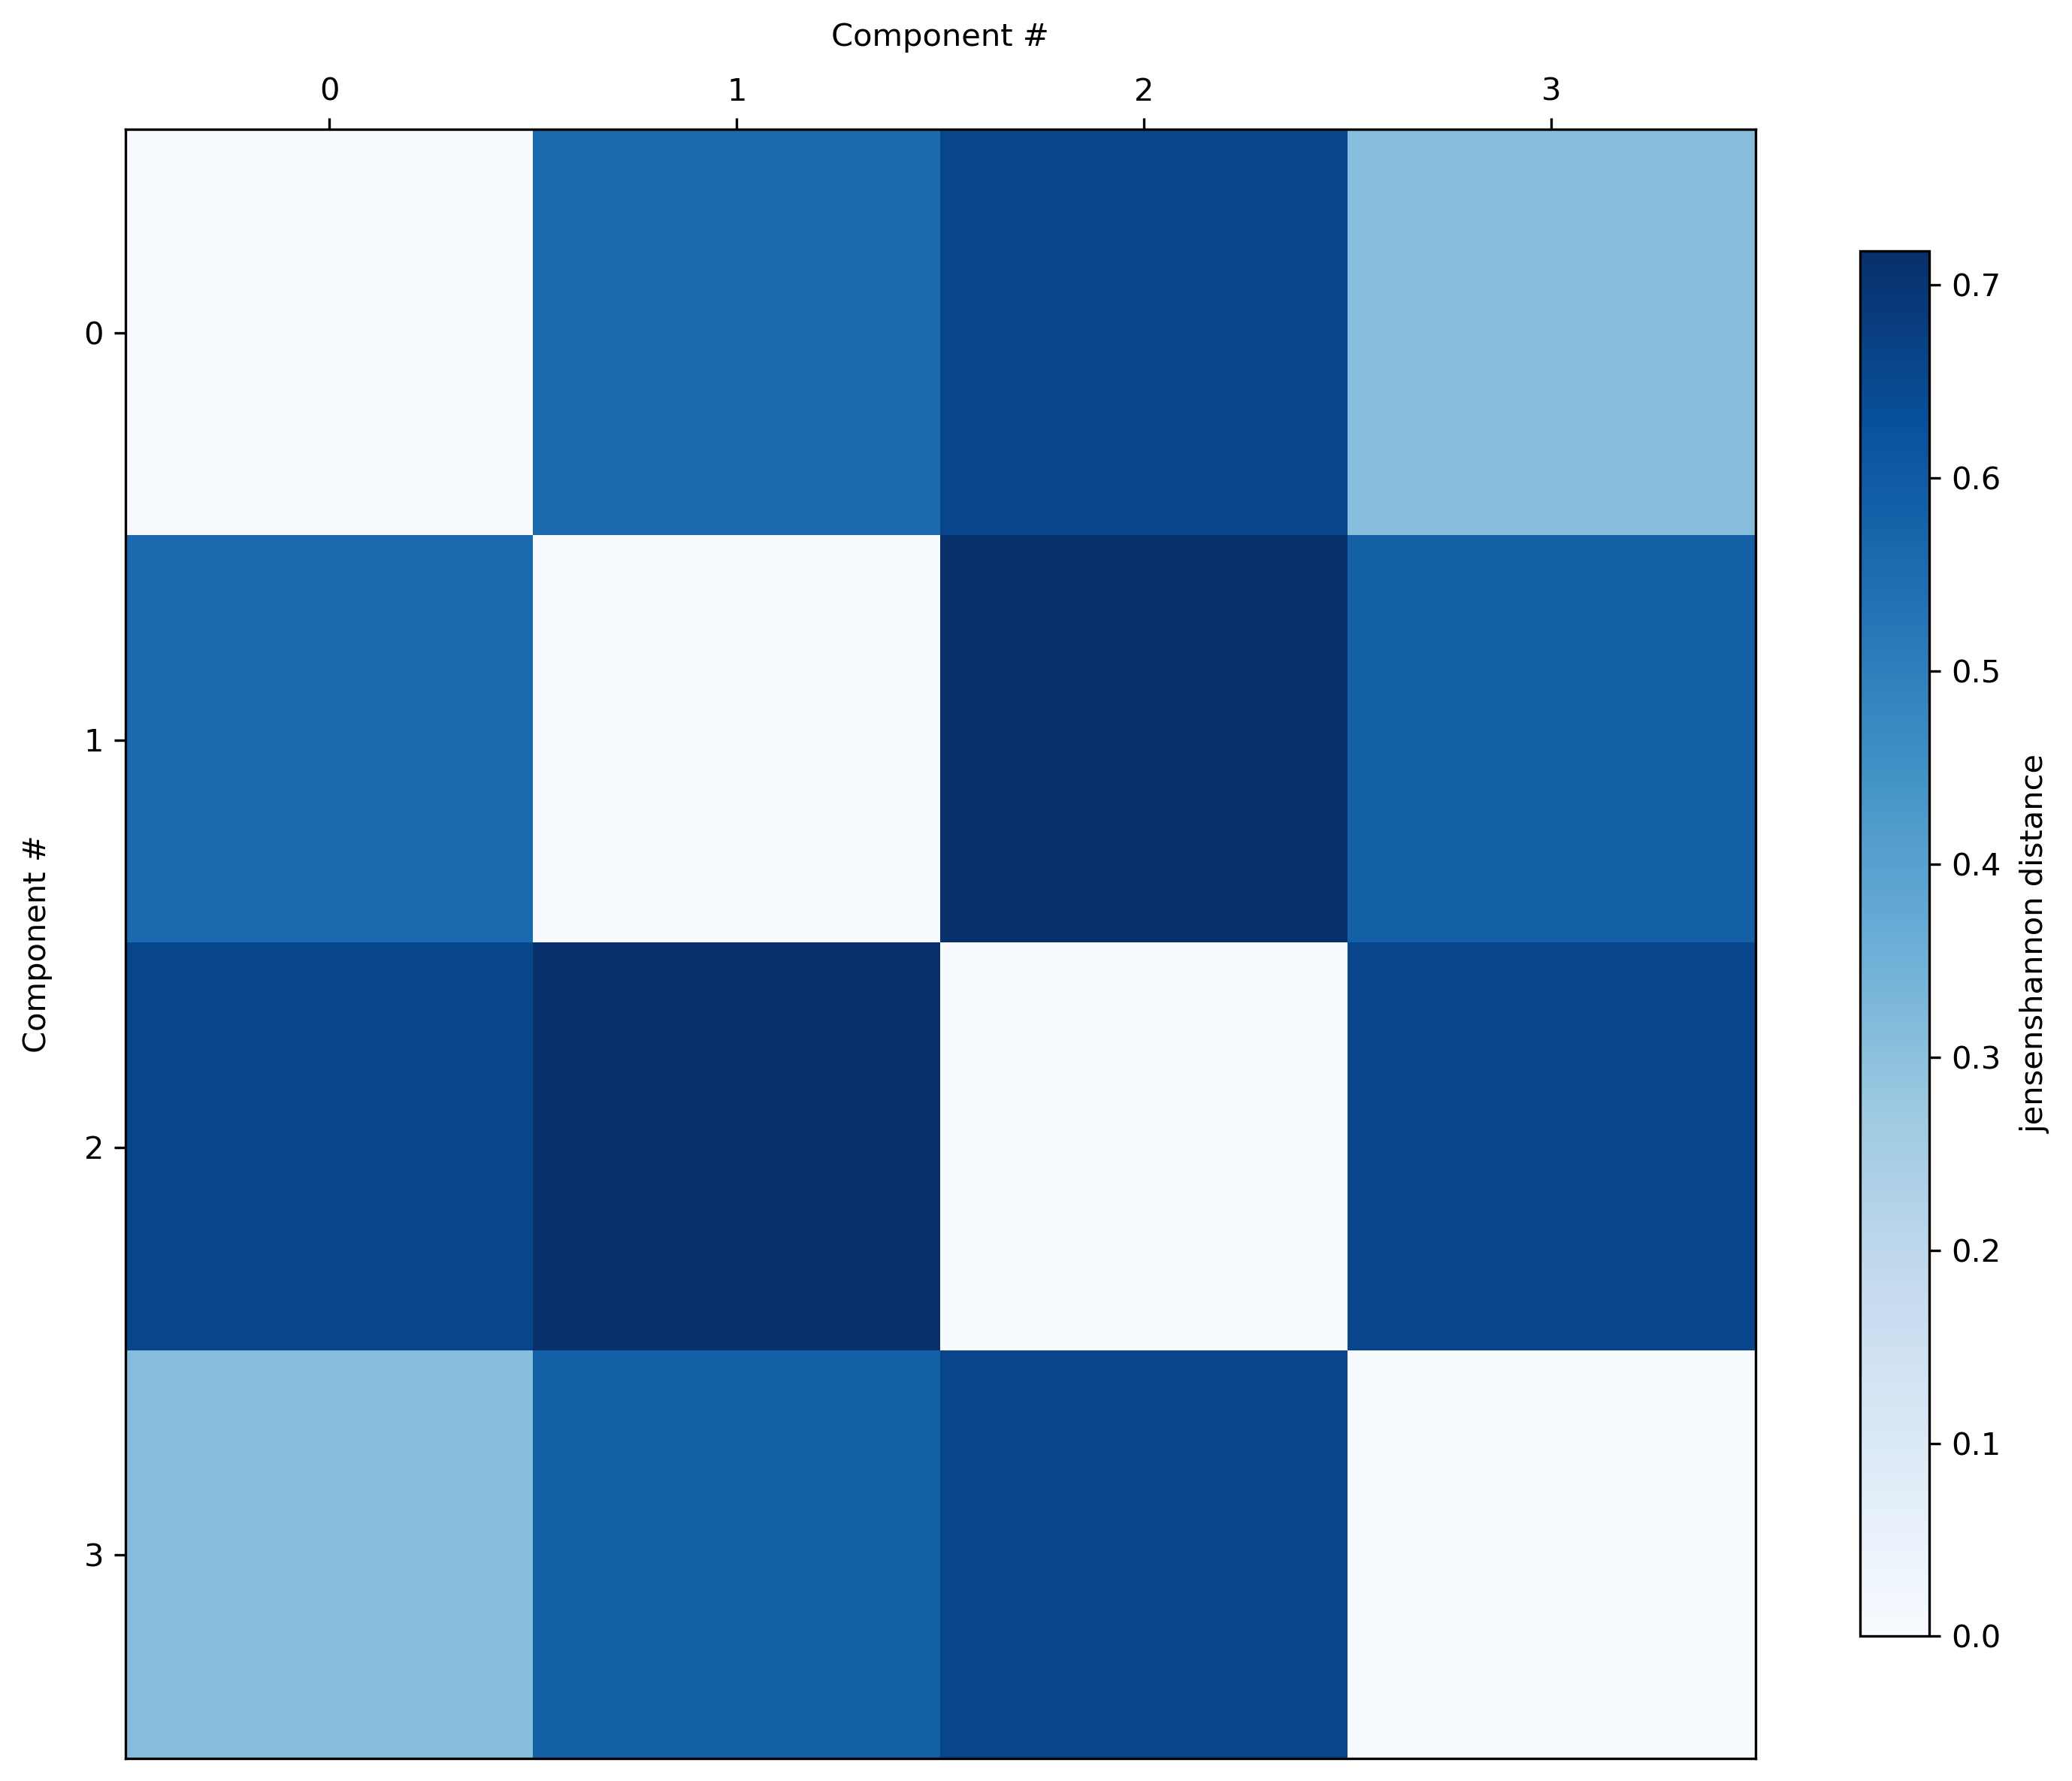

In [15]:
results_sim.divergence(metric="jensenshannon", path_to_save="./results/e888c5/components_divergence.png")
Image(filename=f"./results/{training_id}/components_divergence.png", width=600, height=550)

And the corresponding decomposition matrix, which shows the probability of assignment of each individual proximity map to each component/topic. As seen from the representativity earlier, topics T0 and T4 have items with high assignment probabilities towards them.

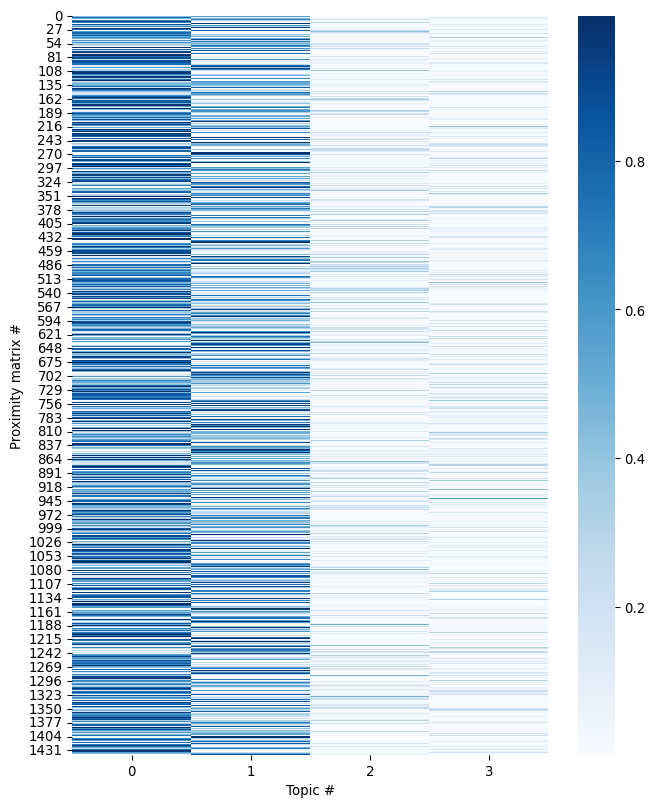

In [17]:
# TODO sorted would be better
fig = results_sim.plot_decomposition(ordered=True)
fig.set_dpi(96)
fig.show()